<a href="https://colab.research.google.com/github/drajdeep572-hawk/credit-risk-loan-default-prediction/blob/main/credit_risk_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**# Credit Risk & Loan Default Prediction**

**Predicting whether a borrower will repay (`0`) or default (`1`) using historical lending data.**

Step 1: Data Inspection & Cleaning
Inspecting missing values, class balance (~78% repaid vs. ~22% default), and removing impossible outliers (`person_age > 80`, `person_emp_length > 60`) and duplicates.\

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (update path if running locally or on Kaggle)
df = pd.read_csv('/content/credit_risk_dataset.csv.zip')

print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nTarget Distribution (0 = Non-Default, 1 = Default):\n", df['loan_status'].value_counts(normalize=True))

# 2. Check summary statistics to spot impossible outliers
display(df.describe())

# 3. Remove unrealistic biological/career outliers
df = df[df['person_age'] <= 80]
df = df[(df['person_emp_length'] <= 60) | (df['person_emp_length'].isnull())]

# Remove duplicate rows if any exist
df = df.drop_duplicates().reset_index(drop=True)
print("\nCleaned Shape:", df.shape)

Dataset Shape: (32581, 12)

Missing Values:
 person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Target Distribution (0 = Non-Default, 1 = Default):
 loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000



Cleaned Shape: (32407, 12)


### Step 2: Exploratory Data Analysis (EDA)
Visualizing default rates across **Loan Grade**, **Home Ownership**, and **Loan-to-Income Ratio** to identify primary risk drivers.

/tmp/ipykernel_551/1031500042.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='loan_grade', y='loan_status', order=['A','B','C','D','E','F','G'], ax=axes[0], palette='Reds')
/tmp/ipykernel_551/1031500042.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='person_home_ownership', y='loan_status', ax=axes[1], palette='Blues')
/tmp/ipykernel_551/1031500042.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y='loan_percent_income', ax=axes[2], palette='Set2')


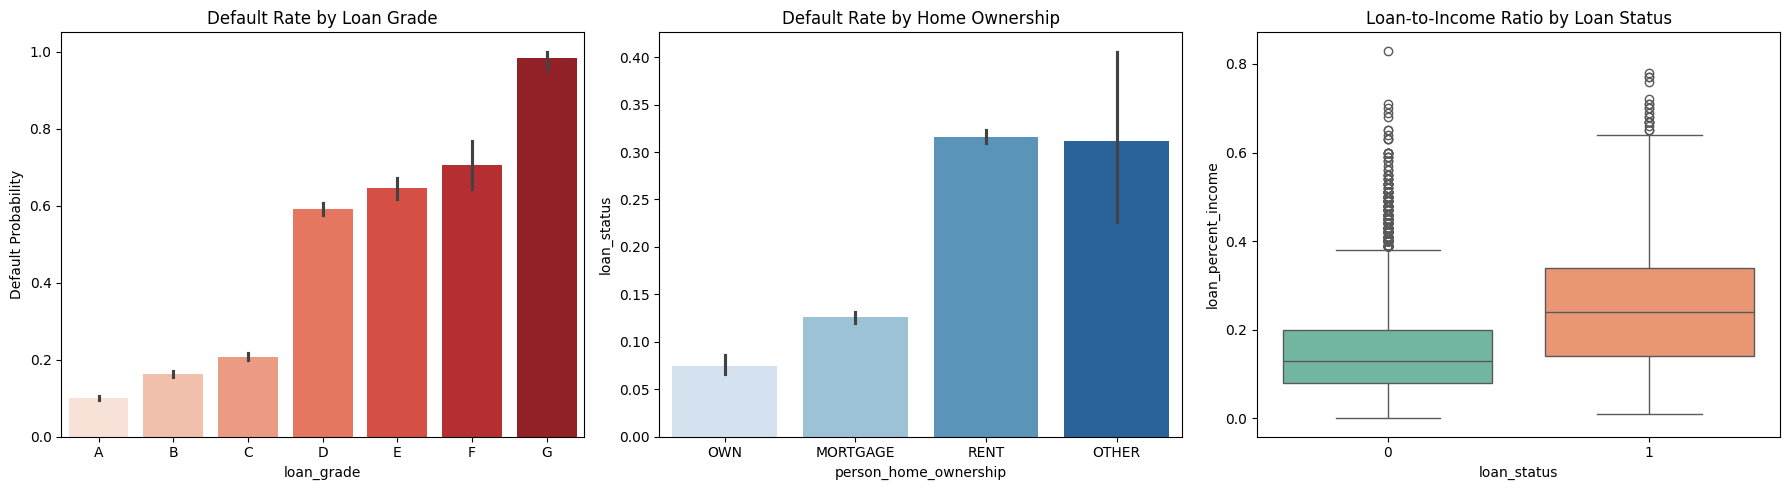

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Default Rate by Loan Grade
sns.barplot(data=df, x='loan_grade', y='loan_status', order=['A','B','C','D','E','F','G'], ax=axes[0], palette='Reds')
axes[0].set_title('Default Rate by Loan Grade')
axes[0].set_ylabel('Default Probability')

# Plot 2: Default Rate by Home Ownership
sns.barplot(data=df, x='person_home_ownership', y='loan_status', ax=axes[1], palette='Blues')
axes[1].set_title('Default Rate by Home Ownership')

# Plot 3: Loan-to-Income Ratio (loan_percent_income) vs Default Status
sns.boxplot(data=df, x='loan_status', y='loan_percent_income', ax=axes[2], palette='Set2')
axes[2].set_title('Loan-to-Income Ratio by Loan Status')

plt.tight_layout()
plt.show()

### Step 3: Feature Engineering & Model Training
Engineering debt-burden ratios, applying leakage-free median imputation, scaling, and one-hot encoding via `ColumnTransformer`, and comparing **Logistic Regression**, **Random Forest**, and **XGBoost**.


=== Logistic Regression (ROC-AUC: 0.8729) ===
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      5064
           1       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.73      0.80      0.75      6482
weighted avg       0.84      0.81      0.82      6482

=== Random Forest (ROC-AUC: 0.9358) ===
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5064
           1       0.96      0.73      0.83      1418

    accuracy                           0.93      6482
   macro avg       0.95      0.86      0.89      6482
weighted avg       0.94      0.93      0.93      6482

=== XGBoost (ROC-AUC: 0.9420) ===
              precision    recall  f1-score   support

           0       0.95      0.94      0.94      5064
           1       0.78      0.81      0.79      1418

    accuracy                           0.91      6482
   macro

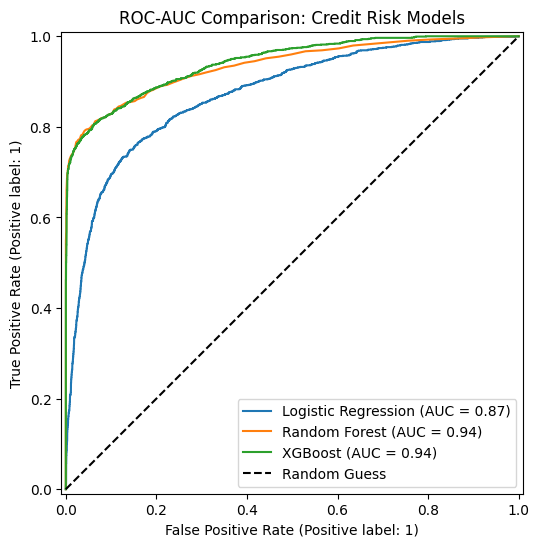

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay

# 1. Feature Engineering (Domain Ratios)
df['income_to_loan_ratio'] = df['person_income'] / (df['loan_amnt'] + 1)
df['estimated_annual_interest'] = df['loan_amnt'] * (df['loan_int_rate'].fillna(df['loan_int_rate'].median()) / 100)
df['interest_to_income_ratio'] = df['estimated_annual_interest'] / (df['person_income'] + 1)

# 2. Define Features (X) and Target (y)
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# 3. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 4. Separate Numeric and Categorical Columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# 5. Build Preprocessing Pipelines (Median Imputation + Scaling / One-Hot Encoding)
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# 6. Define Models (Accounting for ~78/22 Class Imbalance)
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=5, scale_pos_weight=imbalance_ratio, random_state=42, eval_metric='logloss')
}

# 7. Train, Evaluate & Plot ROC-AUC Curves
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    clf = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)
    print(f"=== {name} (ROC-AUC: {auc:.4f}) ===")
    print(classification_report(y_test, y_pred))

    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title('ROC-AUC Comparison: Credit Risk Models')
plt.legend()
plt.show()

### Step 4: Model Evaluation & Threshold Tuning
Evaluating the winning **XGBoost model (0.942 ROC-AUC)** using a confusion matrix, top feature importances, and probability cutoffs (`0.30`–`0.60`) for credit risk policy.

/tmp/ipykernel_551/2821982121.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis', ax=axes[1])


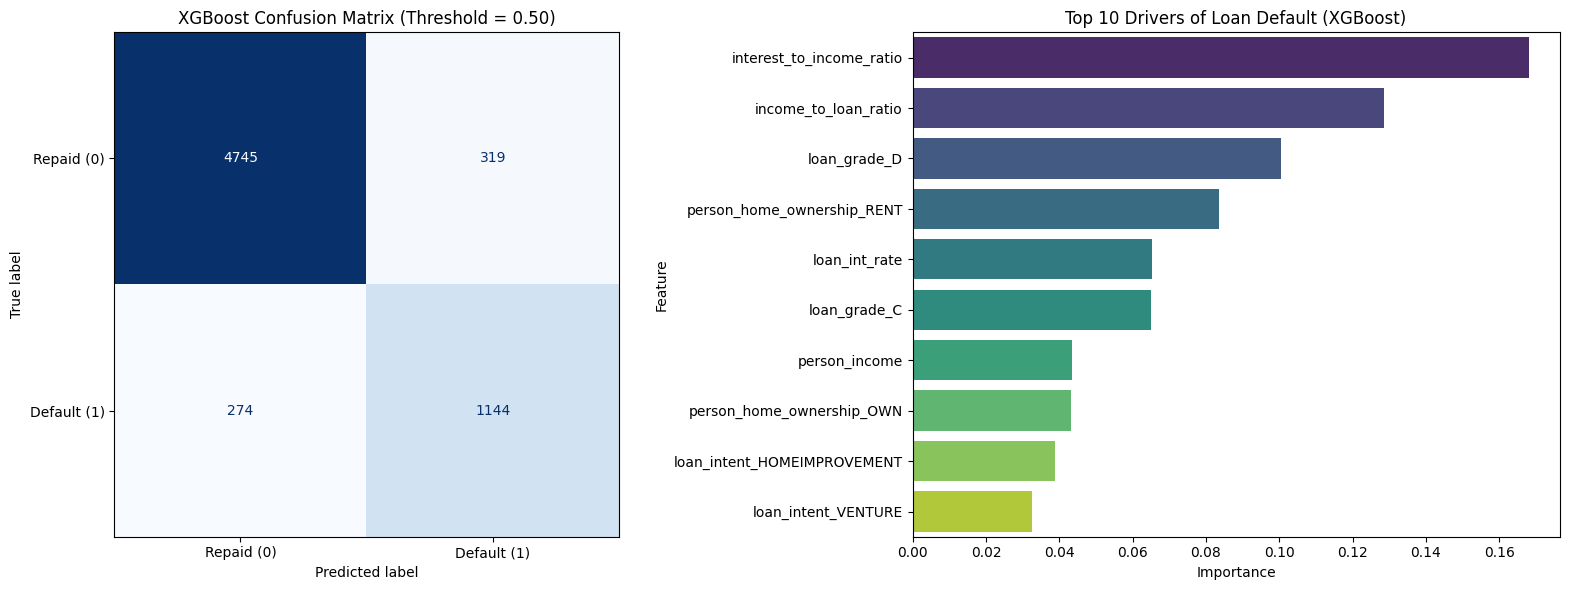

=== Business Risk Threshold Analysis ===
Threshold 0.30 -> Defaulters Caught: 1268/1418 (89.4%) | Flag Precision: 52.9% | Good Borrowers Rejected: 1131
Threshold 0.40 -> Defaulters Caught: 1197/1418 (84.4%) | Flag Precision: 65.6% | Good Borrowers Rejected: 628
Threshold 0.50 -> Defaulters Caught: 1144/1418 (80.7%) | Flag Precision: 78.2% | Good Borrowers Rejected: 319
Threshold 0.60 -> Defaulters Caught: 1095/1418 (77.2%) | Flag Precision: 86.7% | Good Borrowers Rejected: 168


In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Extract the trained XGBoost pipeline
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', models['XGBoost'])
])
xgb_pipeline.fit(X_train, y_train)

# 2. Plot Confusion Matrix & Top 10 Feature Importances side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Confusion Matrix (Default 0.50 Threshold)
y_pred_default = xgb_pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred_default)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Repaid (0)', 'Default (1)'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('XGBoost Confusion Matrix (Threshold = 0.50)')

# Right Plot: Top 10 Most Important Features
feature_names = xgb_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = xgb_pipeline.named_steps['classifier'].feature_importances_

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df['Feature'] = feat_df['Feature'].str.replace('num__', '').str.replace('cat__', '')
feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)

sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis', ax=axes[1])
axes[1].set_title('Top 10 Drivers of Loan Default (XGBoost)')

plt.tight_layout()
plt.show()

# 3. Business Threshold Tuning (Comparing Cutoff Probabilities)
y_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

print("=== Business Risk Threshold Analysis ===")
for thresh in [0.30, 0.40, 0.50, 0.60]:
    preds = (y_probs >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp)
    print(f"Threshold {thresh:.2f} -> Defaulters Caught: {tp}/{tp+fn} ({recall:.1%}) | Flag Precision: {precision:.1%} | Good Borrowers Rejected: {fp}")